# Fine-mapping the *ETS2* locus

Genome-wide association studies (GWAS) map disease risk to genomic intervals, but translating a non-coding association into a biological mechanism faces three hurdles: population linkage disequilibrium (LD) leaves tightly correlated bystander variants statistically indistinguishable from causal alleles, distal enhancers can regulate genes across hundreds of kilobases while skipping closer promoters, and regulatory activity is often restricted to specific primary cell states.

AlphaGenome 2 scores a variant by comparing REF and ALT sequences that differ only at that position, so each candidate's predicted cis-regulatory effect is not confounded by linkage disequilibrium.

Here we dissect the pleiotropic autoimmune association at chr21q22 linked to inflammatory bowel disease, ankylosing spondylitis, primary sclerosing cholangitis, and Takayasu's arteritis ([de Lange et al., *Nature Genetics* 2017](https://doi.org/10.1038/ng.3760); [Stankey et al., *Nature* 2024](https://doi.org/10.1038/s41586-024-07501-1)). The associated interval lies inside an intergenic gene desert with no coding variants, leaving three questions open:

1. **Which variant** among the tightly linked candidates drives the regulatory effect?
2. **Which gene** in the surrounding megabase window is its transcriptional target?
3. **Which intestinal immune lineage** mediates the disease mechanism?

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

## Set up

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)). We initialize the AlphaGenome 2 client (`dna_client.create`) and load canonical MANE Select protein-coding transcripts from GENCODE v46 (GRCh38) to visualize surrounding genes.

In [2]:
# @title Imports
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import track_data
from alphagenome.data import transcript
from alphagenome.interpretation import ism
from alphagenome.models.v2 import dna_client
from alphagenome.models.v2 import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns

dna_model = dna_client.create(colab_utils.get_api_key())

gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf_mane = gene_annotation.filter_to_mane_select_transcript(gtf)
transcript_extractor = transcript.TranscriptExtractor(gtf_mane)

## The chr21q22 credible set and gene-desert architecture

Statistical fine-mapping (SuSiE) of the inflammatory bowel disease GWAS signal (study GCST004133; [Stankey et al., *Nature* 2024](https://doi.org/10.1038/s41586-024-07501-1)) narrows the association to 7 non-coding SNPs spanning just 1.2 kb (chr21:39,093,586-39,094,818). Posterior inclusion probabilities (PIPs) rank rs2836878 first (PIP = 0.25) ahead of rs2836882 (PIP = 0.16). At every candidate SNP, the GRCh38 reference allele is the common risk allele and the alternate allele is protective (negative GWAS beta). At rs2836882, for example, the risk allele G has a frequency of about 75% in Europeans, and the protective allele A has GWAS beta = -0.055. Experiments showed that the risk allele increases enhancer activity and *ETS2* transcription in macrophages ([Stankey et al., *Nature* 2024](https://doi.org/10.1038/s41586-024-07501-1)), so at the causal variant we expect the protective alternate allele to lower predicted *ETS2* expression.

In [3]:
# @title Define the 7 SuSiE fine-mapped IBD variants at chr21q22 (GCST004133)
variants_df = pd.DataFrame(
    [
        ('rs2836878', 'chr21:39093608:G>A', 0.2520, -0.0553),
        ('rs2836882', 'chr21:39094644:G>A', 0.1553, -0.0548),
        ('rs4817986', 'chr21:39093586:G>T', 0.1306, -0.0543),
        ('rs2836883', 'chr21:39094818:G>A', 0.1292, -0.0543),
        ('rs9808651', 'chr21:39094542:G>A', 0.1235, -0.0543),
        ('rs2836881', 'chr21:39094373:G>T', 0.1095, -0.0540),
        ('rs4817987', 'chr21:39093975:C>T', 0.0980, -0.0537),
    ],
    columns=['rsid', 'variant_str', 'pip', 'gwas_beta'],
)
variants_df['variant'] = variants_df['variant_str'].map(genome.Variant.from_str)
variants_df[['rsid', 'variant_str', 'pip', 'gwas_beta']]

,rsid,variant_str,pip,gwas_beta
0,rs2836878,chr21:39093608:G>A,0.2520,-0.0553
1,rs2836882,chr21:39094644:G>A,0.1553,-0.0548
2,rs4817986,chr21:39093586:G>T,0.1306,-0.0543
3,rs2836883,chr21:39094818:G>A,0.1292,-0.0543
4,rs9808651,chr21:39094542:G>A,0.1235,-0.0543
5,rs2836881,chr21:39094373:G>T,0.1095,-0.0540
6,rs4817987,chr21:39093975:C>T,0.0980,-0.0537


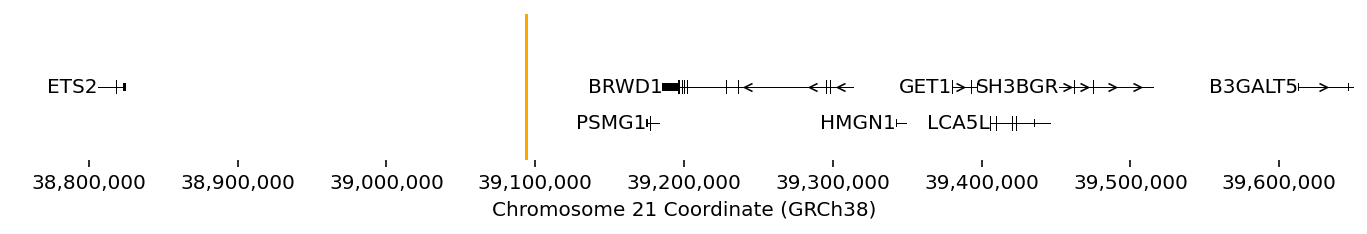

In [4]:
# @title Plot genes and fine-mapped credible set across the chr21q22 locus
locus_interval = genome.Interval('chr21', 38_750_000, 39_650_000)

fig = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(
            transcript_extractor.extract(locus_interval)
        ),
    ],
    interval=locus_interval,
    annotations=[
        plot_components.VariantAnnotation(
            variants_df['variant'].tolist(),
            use_default_labels=False,
            alpha=0.8,
        )
    ],
    fig_width=12,
    xlabel='Chromosome 21 Coordinate (GRCh38)',
)
fig.axes[-1].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)
plt.show()

## Pinpointing the variant, target gene, and immune lineage

To test how each candidate SNP affects gene expression across intestinal immune cells, we select the 7 ileum immune reference conditions listed by `dna_model.supported_conditions()`: two myeloid cell types (ileum macrophage and ileum monocyte) and five lymphoid cell types (ileum B cell, CD4+ T cell, CD8+ T cell, regulatory T cell, and natural killer cell). We score all 49 variant-condition pairs in a single batch call with `dna_model.score_variants` using a centered 1 Mb sequence context (`dna_client.SEQUENCE_LENGTH_1MB`) and tidy observed protein-coding expression scores with `variant_scorers.tidy_scores`.

In [5]:
# @title Score 7 credible-set variants across 7 ileum immune reference conditions

ILEUM_CELL_MAP = {
    'ileum macrophage': 'Macrophage',
    'ileum monocyte': 'Monocyte',
    'ileum B cell': 'B cell',
    'ileum CD4-positive, alpha-beta T cell': 'CD4 T',
    'ileum CD8-positive, alpha-beta T cell': 'CD8 T',
    'ileum regulatory T cell': 'Treg',
    'ileum natural killer cell': 'NK',
}

supported_df = dna_model.supported_conditions()
ileum_conditions_df = supported_df[
    supported_df['biosample_name'].isin(ILEUM_CELL_MAP)
].set_index('biosample_name')
cell_to_condition = ileum_conditions_df.loc[
    list(ILEUM_CELL_MAP), 'condition'
].to_dict()

intervals_batch = []
variants_batch = []
conditions_batch = []
for _, vrow in variants_df.iterrows():
  var = vrow['variant']
  interval_1mb = var.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
  for cond_curie in cell_to_condition.values():
    intervals_batch.append(interval_1mb)
    variants_batch.append(var)
    conditions_batch.append(cond_curie)

scores_batch = dna_model.score_variants(
    intervals=intervals_batch,
    variants=variants_batch,
    variant_scorers=[
        variant_scorers.RECOMMENDED_VARIANT_SCORERS['SC_GENE_EXPRESSION'],
    ],
    conditions=conditions_batch,
)

tidy_df = variant_scorers.tidy_scores(scores_batch, filter_protein_coding=True)
variant_to_rsid = dict(zip(variants_df['variant_str'], variants_df['rsid']))
tidy_df['rsid'] = tidy_df['variant_id'].astype(str).map(variant_to_rsid)

expr_df = tidy_df[
    (tidy_df['output_type'] == 'SC_GENE_EXPRESSION')
    & (tidy_df['imputation_mode'] == 'observed')
].copy()
expr_summary = (
    expr_df.groupby(['rsid', 'biosample_name', 'gene_name'], as_index=False)[
        'raw_score'
    ]
    .mean()
    .assign(abs_raw_score=lambda d: d['raw_score'].abs())
    .sort_values('abs_raw_score', ascending=False)
    .reset_index(drop=True)
)
expr_summary[['rsid', 'biosample_name', 'gene_name', 'raw_score']].head(8)

  0%|          | 0/49 [00:00<?, ?it/s]

,rsid,biosample_name,gene_name,raw_score
0,rs2836882,ileum monocyte,ETS2,-0.280190
1,rs2836882,ileum macrophage,ETS2,-0.227641
2,rs2836882,ileum monocyte,PSMG1,-0.056864
3,rs2836882,ileum macrophage,PSMG1,-0.029903
4,rs2836882,ileum macrophage,GET1-SH3BGR,0.023667
5,rs9808651,ileum macrophage,ETS2,-0.021754
6,rs2836882,ileum monocyte,GET1-SH3BGR,0.018216
7,rs2836881,"ileum CD8-positive, alpha-beta T cell",SH3BGR,-0.012822


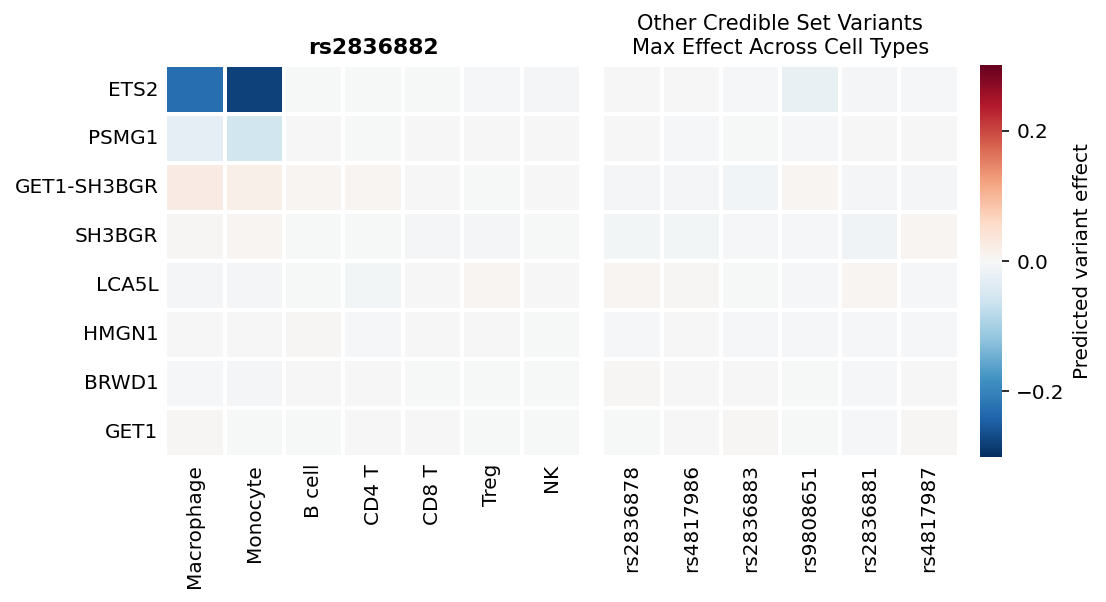

In [6]:
# @title Plot predicted gene expression log-fold change across genes, cell types, and variants
CANDIDATE_GENES = [
    'ETS2',
    'PSMG1',
    'GET1-SH3BGR',
    'SH3BGR',
    'LCA5L',
    'HMGN1',
    'BRWD1',
    'GET1',
]
OTHER_RSIDS = [
    'rs2836878',
    'rs4817986',
    'rs2836883',
    'rs9808651',
    'rs2836881',
    'rs4817987',
]

rs283_df = expr_summary[expr_summary['rsid'] == 'rs2836882'].assign(
    cell_label=lambda d: d['biosample_name'].map(ILEUM_CELL_MAP)
)
left_mat = rs283_df.pivot(
    index='gene_name', columns='cell_label', values='raw_score'
).reindex(index=CANDIDATE_GENES, columns=list(ILEUM_CELL_MAP.values()))

other_df = expr_summary[expr_summary['rsid'].isin(OTHER_RSIDS)]
idx_max = other_df.groupby(['gene_name', 'rsid'])['abs_raw_score'].idxmax()
right_mat = (
    other_df.loc[idx_max]
    .pivot(index='gene_name', columns='rsid', values='raw_score')
    .reindex(index=CANDIDATE_GENES, columns=OTHER_RSIDS)
)

fig, (ax_left, ax_right, ax_cbar) = plt.subplots(
    1,
    3,
    figsize=(7.5, 3.6),
    gridspec_kw={'width_ratios': [7, 6, 0.38], 'wspace': 0.08},
)
sns.heatmap(
    left_mat,
    ax=ax_left,
    cmap='RdBu_r',
    vmin=-0.3,
    vmax=0.3,
    center=0.0,
    cbar=False,
    linewidths=1.2,
    linecolor='white',
)
ax_left.set_title('rs2836882', fontsize=11, fontweight='bold', pad=6)
ax_left.set_xlabel('')
ax_left.set_ylabel('')
ax_left.tick_params(axis='both', which='both', length=0)
ax_left.set_xticklabels(ax_left.get_xticklabels(), rotation=90)

sns.heatmap(
    right_mat,
    ax=ax_right,
    cmap='RdBu_r',
    vmin=-0.3,
    vmax=0.3,
    center=0.0,
    cbar=True,
    cbar_ax=ax_cbar,
    cbar_kws={'label': 'Predicted variant effect', 'ticks': [-0.2, 0.0, 0.2]},
    yticklabels=False,
    linewidths=1.2,
    linecolor='white',
)
ax_right.set_title(
    'Other Credible Set Variants\nMax Effect Across Cell Types',
    fontsize=10.5,
    pad=6,
)
ax_right.set_xlabel('')
ax_right.set_ylabel('')
ax_right.tick_params(axis='both', which='both', length=0)
ax_right.set_xticklabels(ax_right.get_xticklabels(), rotation=90)
plt.show()

One batch of variant scores gives a prediction for each of the three questions, and each prediction agrees with the experimental dissection of the locus ([Stankey et al., *Nature* 2024](https://doi.org/10.1038/s41586-024-07501-1)):

1. **Variant (rs2836882)**: Although it ranks second by fine-mapping (PIP = 0.16), rs2836882 (G>A) is predicted to strongly reduce *ETS2* expression in ileum macrophages, while the lead SNP rs2836878 (PIP = 0.25) and the other candidates have little predicted effect. This agrees with tiling MPRA across the 2 kb region in primary macrophages.
2. **Distal target gene (*ETS2*)**: *ETS2* (~289 kb upstream) is the selective transcriptional target, while closer genes such as *PSMG1* (78 kb downstream) and *BRWD1* (137 kb downstream) show negligible change, consistent with promoter-capture Hi-C looping and CRISPR-Cas9 deletion of the 1.85 kb intergenic enhancer in primary human monocytes.
3. **Myeloid lineage specificity**: The predicted reduction in *ETS2* expression occurs specifically in **macrophages and monocytes** and is absent across B, T, regulatory T, and NK cells, matching active H3K27ac enrichment at this enhancer exclusively in human monocytes and macrophages.

## Enhancer chromatin accessibility across ileum immune lineages

To inspect the local regulatory element directly, we call `dna_model.predict_variants` for rs2836882 across all 7 ileum immune reference conditions and slice predicted `SC_ATAC` profiles to a 1 kb window centered on the variant (chr21:39,094,144-39,095,144).

In [7]:
# @title Predict 1 kb REF vs. ALT enhancer accessibility (SC_ATAC) around rs2836882

causal_var = genome.Variant.from_str('chr21:39094644:G>A')
interval_1mb = causal_var.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
enhancer_interval = causal_var.reference_interval.resize(1000)

conditions = list(cell_to_condition.values())
variant_outputs = dna_model.predict_variants(
    intervals=interval_1mb,
    variants=[causal_var] * len(conditions),
    conditions=conditions,
    requested_outputs=[dna_client.OutputType.SC_ATAC],
)

atac_ref = track_data.concat([o.reference.sc_atac for o in variant_outputs])
atac_alt = track_data.concat([o.alternate.sc_atac for o in variant_outputs])
atac_mask = (
    (atac_ref.metadata['Assay title'] == 'scATAC-seq 10X')
    & (atac_ref.metadata['data_pipeline'] == 'cellranger')
).to_numpy()
atac_pred_ref = atac_ref[:, atac_mask].slice_by_interval(enhancer_interval)
atac_pred_alt = atac_alt[:, atac_mask].slice_by_interval(enhancer_interval)

  0%|          | 0/7 [00:00<?, ?it/s]

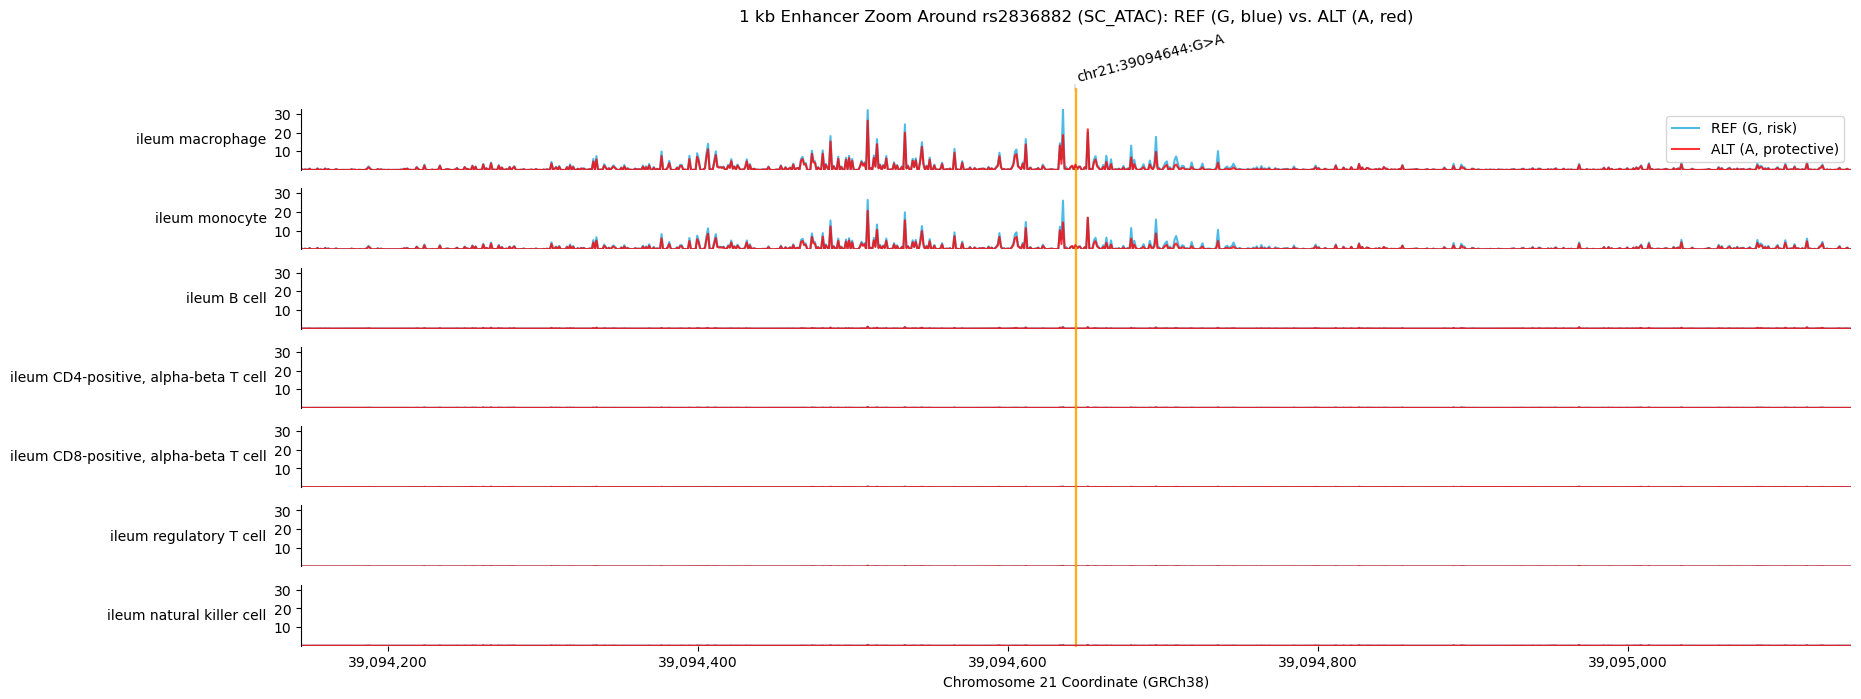

In [7]:
# @title Plot 1 kb REF vs. ALT enhancer accessibility across ileum immune cell types
fig = plot_components.plot(
    [
        plot_components.OverlaidTracks(
            tdata={'REF (G, risk)': atac_pred_ref, 'ALT (A, protective)': atac_pred_alt},
            colors={'REF (G, risk)': '#22AAE1', 'ALT (A, protective)': 'red'},
            ylabel_template='{biosample_name}',
            shared_y_scale=True,
        ),
    ],
    interval=enhancer_interval,
    annotations=[plot_components.VariantAnnotation([causal_var], alpha=0.8)],
    xlabel='Chromosome 21 Coordinate (GRCh38)',
    title='1 kb Enhancer Zoom Around rs2836882 (SC_ATAC): REF (G, blue) vs. ALT (A, red)',
)
fig.axes[-1].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)
plt.show()

## Base-resolution motif dissection via in silico mutagenesis

Finally, we run `dna_model.score_ism_variants` over the 64 bp around rs2836882 in ileum macrophages to see which bases most affect predicted *ETS2* expression.

In [9]:
# @title Run 64 bp ISM around rs2836882 scoring ETS2 expression in ileum macrophage

ism_interval = causal_var.reference_interval.resize(64)
ism_scores_raw = dna_model.score_ism_variants(
    interval=interval_1mb,
    ism_interval=ism_interval,
    variant_scorers=[
        variant_scorers.RECOMMENDED_VARIANT_SCORERS['SC_GENE_EXPRESSION']
    ],
    condition=cell_to_condition['ileum macrophage'],
)

v0 = ism_scores_raw[0][0]
ets2_obs_idx = int(np.where((v0.obs['gene_name'] == 'ETS2').to_numpy())[0][0])
sc10x3_var_idx = int(
    np.where(
        (
            (v0.var['imputation_mode'] == 'observed')
            & (v0.var['Assay title'] == 'scRNA-seq 10X 3')
        ).to_numpy()
    )[0][0]
)

ism_matrix = ism.ism_matrix(
    [float(v[0].X[ets2_obs_idx, sc10x3_var_idx]) for v in ism_scores_raw],
    variants=[v[0].uns['variant'] for v in ism_scores_raw],
)

  0%|          | 0/7 [00:00<?, ?it/s]

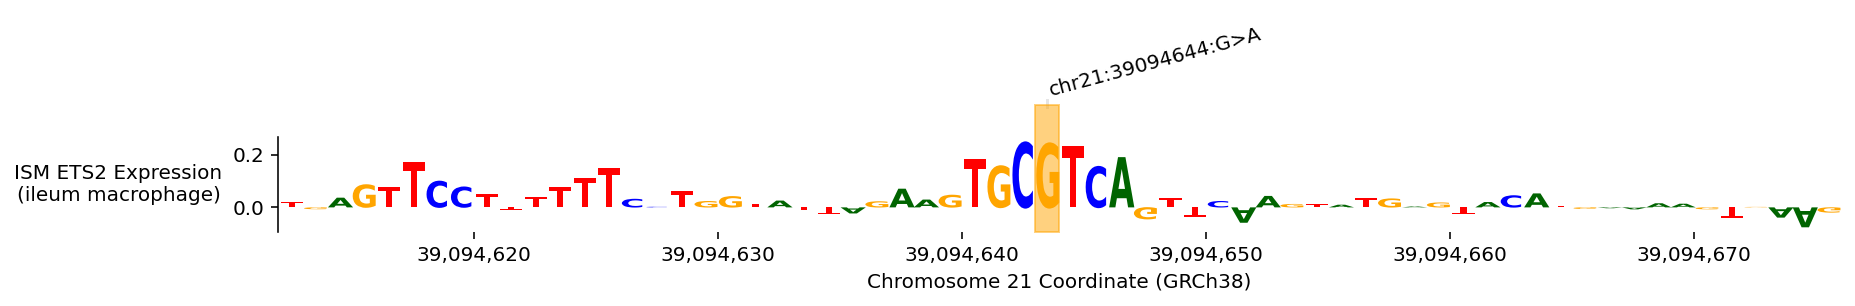

In [10]:
# @title Plot 64 bp ISM sequence logo around rs2836882
fig = plot_components.plot(
    [
        plot_components.SeqLogo(
            scores=ism_matrix,
            scores_interval=ism_interval,
            ylabel='ISM ETS2 Expression\n(ileum macrophage)',
        )
    ],
    interval=ism_interval,
    annotations=[plot_components.VariantAnnotation([causal_var], alpha=0.5)],
    fig_width=14,
    xlabel='Chromosome 21 Coordinate (GRCh38)',
)
fig.axes[-1].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)
plt.show()

ISM highlights a short AP-1-like motif (5'-TGCGTCA-3') that overlaps rs2836882 at the center of the predicted enhancer peak.

This fits the experimental data. In heterozygous primary macrophages ([Stankey et al., *Nature* 2024](https://doi.org/10.1038/s41586-024-07501-1)), rs2836882 does not fall in a core PU.1 motif, yet the risk G allele shows more than 4-fold stronger PU.1 binding, higher accessibility, and 2.5-fold higher H3K27ac. One explanation is cooperative recruitment of AP-1 factors and PU.1 at the *ETS2* enhancer.